# Assignment 6: Statistics for Data Science

| | |
|---|---|
| **Student** | Lokesh Patwal |
| **Programme** | Yuva Intern - Data Science Fundamentals Assessment |
| **Assignment** | 6 of 10 |

## 2. Aim
To calculate and interpret descriptive statistics (centre, spread, shape and relationships) on a real chemical-analysis dataset, and to check hand-written formulas against NumPy and SciPy.

## 3. Objectives
1. Explain population versus sample.
2. Compute mean, median and mode.
3. Compute variance and standard deviation with `ddof=0` and `ddof=1`.
4. Compute quartiles, IQR and outliers.
5. Measure skewness, covariance and correlation.
6. Draw histograms and a box plot to support the numbers.

## 4. Introduction and Theory
* **Population** = every member of a group; **sample** = a part of it. Formulas for a sample divide by `n - 1` (Bessel's correction) so that the variance is not underestimated.
* **Mean** = sum / n (sensitive to extreme values). **Median** = middle value (robust). **Mode** = most frequent value.
* **Variance** = average squared distance from the mean; **standard deviation** = its square root, in the original units.
* **Quartiles** Q1, Q2, Q3 split sorted data into four parts; **IQR** = Q3 - Q1. The IQR rule marks values below Q1 - 1.5 IQR or above Q3 + 1.5 IQR as *possible* outliers.
* **Skewness** > 0 means a longer right tail; < 0 a longer left tail.
* **Covariance** shows whether two variables move together (its size depends on units). **Pearson correlation** `r` rescales it to -1 ... +1.
* **Correlation is not causation.**

## 5. Software and Libraries Required
Python 3, NumPy, pandas, SciPy, Matplotlib, scikit-learn (to load the dataset).

## 6. Dataset Details
**Wine dataset** (Forina et al., 1991; UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/109/wine, also distributed with scikit-learn). 178 wines grown in the same region of Italy from 3 different cultivars (grape varieties). 13 chemical measurements (alcohol, malic acid, flavanoids, proline ...) and the cultivar class. No missing values. A copy is saved to `data/raw/wine.csv`.

## 7. Step-by-Step Procedure
1. Load the data. 2. Population vs sample. 3. Centre. 4. Spread. 5. Quartiles and outliers. 6. Shape. 7. Covariance and correlation. 8. Charts. 9. Validate.

## 8. Complete Python Code and 9. Expected Output
The output under each code cell is the actual output produced when this notebook was executed.

### Step 1: Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_wine

wine_bunch = load_wine(as_frame=True)
wine = wine_bunch.frame.copy()
wine["cultivar"] = wine.pop("target").map(dict(enumerate(["class_0", "class_1", "class_2"])))
Path("../data/raw").mkdir(parents=True, exist_ok=True)
Path("../visualizations").mkdir(exist_ok=True)
wine.to_csv("../data/raw/wine.csv", index=False)

print("Shape:", wine.shape, "| missing values:", int(wine.isna().sum().sum()))
print(wine["cultivar"].value_counts().sort_index().to_string())
display(wine.head(3))

Shape: (178, 14) | missing values: 0
cultivar
class_0    59
class_1    71
class_2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0


### Step 2: Population versus sample
We treat the 178 wines as our *population* and then draw a random *sample* of 30 wines, to see how a sample estimate behaves.

In [2]:
alcohol = wine["alcohol"]
sample = alcohol.sample(n=30, random_state=42)
print(f"Population mean (n=178): {alcohol.mean():.4f}")
print(f"Sample mean     (n=30) : {sample.mean():.4f}")
print(f"Difference             : {sample.mean() - alcohol.mean():+.4f}")

# Repeat sampling 1000 times: the average of sample means lands very close to the population mean
rng = np.random.default_rng(42)
means = [rng.choice(alcohol.to_numpy(), size=30, replace=False).mean() for _ in range(1000)]
print(f"Average of 1000 sample means: {np.mean(means):.4f}  (std of those means: {np.std(means, ddof=1):.4f})")

Population mean (n=178): 13.0006
Sample mean     (n=30) : 13.0107
Difference             : +0.0100
Average of 1000 sample means: 13.0002  (std of those means: 0.1438)


### Step 3: Mean, median and mode

In [3]:
col = wine["magnesium"]
print(f"Mean   : {col.mean():.3f}")
print(f"Median : {col.median():.3f}")
print(f"Mode   : {col.mode().tolist()}")
print(f"Mean - median = {col.mean() - col.median():+.3f}  (a positive gap hints at a right tail)")

# Trimmed mean: ignore the most extreme 10% at both ends
print(f"10% trimmed mean: {stats.trim_mean(col, 0.1):.3f}")

Mean   : 99.742
Median : 98.000
Mode   : [88.0]
Mean - median = +1.742  (a positive gap hints at a right tail)
10% trimmed mean: 98.444


### Step 4: Variance and standard deviation (ddof 0 and 1)

In [4]:
x = col.to_numpy()
n = len(x)
manual_pop_var = ((x - x.mean()) ** 2).sum() / n
manual_sample_var = ((x - x.mean()) ** 2).sum() / (n - 1)

print(f"Population variance (ddof=0): manual {manual_pop_var:.4f} | numpy {np.var(x, ddof=0):.4f}")
print(f"Sample variance     (ddof=1): manual {manual_sample_var:.4f} | numpy {np.var(x, ddof=1):.4f} | pandas {col.var():.4f}")
print(f"Sample std (ddof=1): {np.std(x, ddof=1):.4f} | population std (ddof=0): {np.std(x, ddof=0):.4f}")
print(f"Range: {x.max() - x.min():.0f}  (min {x.min():.0f}, max {x.max():.0f})")
print(f"Coefficient of variation: {np.std(x, ddof=1) / x.mean() * 100:.1f}%")

Population variance (ddof=0): manual 202.8433 | numpy 202.8433
Sample variance     (ddof=1): manual 203.9893 | numpy 203.9893 | pandas 203.9893
Sample std (ddof=1): 14.2825 | population std (ddof=0): 14.2423
Range: 92  (min 70, max 162)
Coefficient of variation: 14.3%


### Step 5: Quartiles, IQR and outliers

In [5]:
q1, q2, q3 = np.percentile(x, [25, 50, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = np.sort(x[(x < lower) | (x > upper)])
print(f"Q1 = {q1}, median = {q2}, Q3 = {q3}, IQR = {iqr}")
print(f"Fences: {lower} to {upper}")
print("Outliers by the IQR rule:", outliers.tolist())

summary = wine[["alcohol", "malic_acid", "magnesium", "proline"]].describe().round(2)
display(summary)

Q1 = 88.0, median = 98.0, Q3 = 107.0, IQR = 19.0
Fences: 59.5 to 135.5
Outliers by the IQR rule: [136.0, 139.0, 151.0, 162.0]


,alcohol,malic_acid,magnesium,proline
count,178.00,178.00,178.00,178.00
mean,13.00,2.34,99.74,746.89
std,0.81,1.12,14.28,314.91
min,11.03,0.74,70.00,278.00
25%,12.36,1.60,88.00,500.50
50%,13.05,1.87,98.00,673.50
75%,13.68,3.08,107.00,985.00
max,14.83,5.80,162.00,1680.00


### Step 6: Shape - skewness

In [6]:
skew = wine.drop(columns="cultivar").skew().sort_values()
display(skew.round(2).to_frame("skewness").T)
print("Most right-skewed:", skew.idxmax(), round(skew.max(), 2))
print("Most left-skewed :", skew.idxmin(), round(skew.min(), 2))
assert abs(stats.skew(wine["proline"], bias=False) - wine["proline"].skew()) < 1e-9

,od280/od315_of_diluted_wines,ash,alcohol,hue,flavanoids,total_phenols,alcalinity_of_ash,nonflavanoid_phenols,proanthocyanins,proline,color_intensity,malic_acid,magnesium
skewness,-0.31,-0.18,-0.05,0.02,0.03,0.09,0.21,0.45,0.52,0.77,0.87,1.04,1.1


Most right-skewed: magnesium 1.1
Most left-skewed : od280/od315_of_diluted_wines -0.31


### Step 7: Covariance and correlation

In [7]:
a, b = wine["flavanoids"].to_numpy(), wine["total_phenols"].to_numpy()
cov_manual = ((a - a.mean()) * (b - b.mean())).sum() / (len(a) - 1)
r_manual = cov_manual / (a.std(ddof=1) * b.std(ddof=1))
r_scipy, p_value = stats.pearsonr(a, b)
rho, _ = stats.spearmanr(a, b)
print(f"Covariance (manual) : {cov_manual:.4f} | numpy: {np.cov(a, b)[0, 1]:.4f}")
print(f"Pearson r  (manual) : {r_manual:.4f} | scipy: {r_scipy:.4f} (p = {p_value:.2e})")
print(f"Spearman rho        : {rho:.4f}")

corr = wine.drop(columns="cultivar").corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values()
print("\nStrongest negative pair:", pairs.index[0], round(pairs.iloc[0], 3))
print("Strongest positive pair:", pairs.index[-1], round(pairs.iloc[-1], 3))

Covariance (manual) : 0.5405 | numpy: 0.5405
Pearson r  (manual) : 0.8646 | scipy: 0.8646 (p = 1.76e-54)
Spearman rho        : 0.8794

Strongest negative pair: ('malic_acid', 'hue') -0.561
Strongest positive pair: ('total_phenols', 'flavanoids') 0.865


### Step 8: Charts to support the numbers

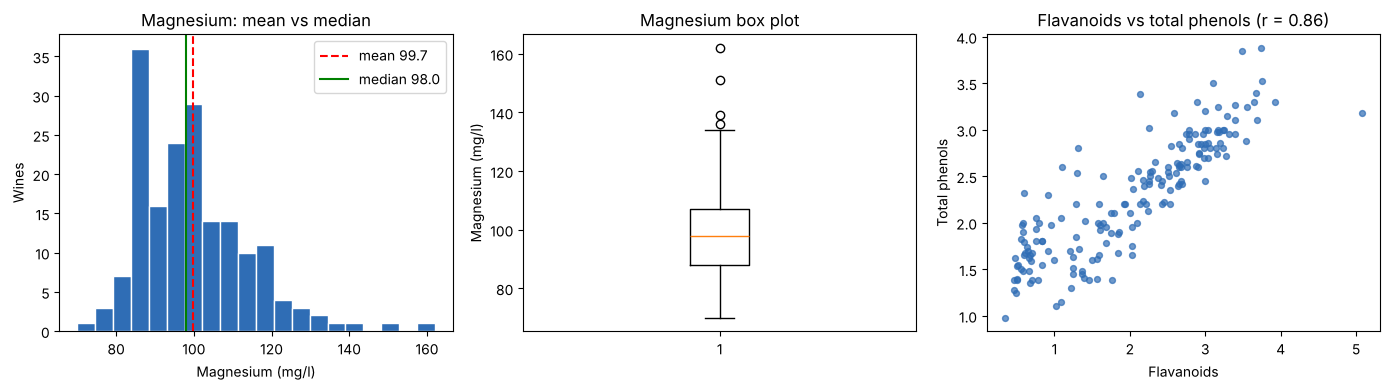

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(wine["magnesium"], bins=20, color="#2F6DB5", edgecolor="white")
axes[0].axvline(col.mean(), color="red", linestyle="--", label=f"mean {col.mean():.1f}")
axes[0].axvline(col.median(), color="green", linestyle="-", label=f"median {col.median():.1f}")
axes[0].set(title="Magnesium: mean vs median", xlabel="Magnesium (mg/l)", ylabel="Wines")
axes[0].legend()

axes[1].boxplot(wine["magnesium"])
axes[1].set(title="Magnesium box plot", ylabel="Magnesium (mg/l)")

axes[2].scatter(wine["flavanoids"], wine["total_phenols"], s=18, alpha=0.7, color="#2F6DB5")
axes[2].set(title=f"Flavanoids vs total phenols (r = {r_scipy:.2f})", xlabel="Flavanoids", ylabel="Total phenols")
fig.tight_layout()
fig.savefig("../visualizations/a6_statistics_overview.png", dpi=150)
plt.show()

### Step 9: Validation checks

In [9]:
assert wine.shape == (178, 14)
assert abs(manual_pop_var - np.var(x)) < 1e-9 and abs(manual_sample_var - col.var()) < 1e-9
assert abs(manual_sample_var / manual_pop_var - n / (n - 1)) < 1e-12
assert abs(r_manual - r_scipy) < 1e-12 and abs(r_manual - np.corrcoef(a, b)[0, 1]) < 1e-12
assert abs(cov_manual - np.cov(a, b)[0, 1]) < 1e-12
assert lower < q1 < q2 < q3 < upper
print("All validation checks passed.")

All validation checks passed.


## 10. Output Explanation
* **Step 2:** the population mean alcohol content is `13.001` % and the 30-wine sample gives `13.011` %. The average of 1000 repeated samples is `13.000` %, which shows that sample means centre on the true mean.
* **Step 3:** magnesium has mean `99.74` and median `98.00`; the mean is slightly higher because a few high values pull it up.
* **Step 4:** the sample variance (`n - 1`) is `203.99` and the population variance (`n`) is `202.84`. Their ratio is exactly `n / (n - 1)` = `1.0056`.
* **Step 5:** the IQR rule marks `4` magnesium values as possible outliers: `[136.0, 139.0, 151.0, 162.0]`. An outlier is *unusual*, not automatically *wrong*; these are plausible measurements.
* **Step 6:** `magnesium` is the most right-skewed feature (skewness `1.10`).
* **Step 7:** flavanoids and total phenols have a strong positive correlation of `0.865`. The manual formula, NumPy and SciPy all agree.

## 11. Observations and Analysis
* When mean and median are close the distribution is roughly symmetric; a bigger gap signals skew or outliers.
* Using `ddof=1` increases the variance slightly. The effect is small for large `n` but matters for small samples.
* Correlation is a *linear* measure. Spearman's rho (rank-based) is a useful second check; here it is 0.879 against Pearson's 0.865.
* A strong correlation between two chemical measurements may mean they carry overlapping information; this is called multicollinearity and matters when building models.
* Correlation does not prove that one measurement causes the other.

**Common mistakes**
| Mistake | Fix |
|---|---|
| Using `np.var` default for a sample | Pass `ddof=1` |
| Deleting every outlier automatically | Investigate first; delete only if it is an error |
| Reading correlation as causation | Treat it as an association |

**Practice tasks**
1. Calculate the coefficient of variation of every feature and rank them.
2. Compare the mean proline of the three cultivars.
3. Find the pair of features with correlation closest to zero.

## 12. Result / Conclusion
Descriptive statistics were calculated by hand and with libraries, and every result matched. The Wine data showed strongly related chemical measurements and some mild skew. Choosing the right measure (mean vs median, population vs sample) and checking results with a second method are essential habits for trustworthy analysis.